In [1]:

# Experiment 08: Robust Drift Detection Evaluation
# Reproducible environment and configuration

import os
import random
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 2026
random.seed(SEED)
np.random.seed(SEED)

print("Experiment 08: Robust Drift Detection Evaluation")
print("-" * 55)
print("Python version:", platform.python_version())
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Random seed:", SEED)
print("Working directory:", os.getcwd())

# Planned experiment settings
WINDOW_SIZE = 20
DRIFT_STRENGTHS = [0.00, 0.05, 0.10, 0.20, 0.35]
N_TRIALS = 30

print("\nConfiguration")
print("Window size:", WINDOW_SIZE)
print("Drift strengths:", DRIFT_STRENGTHS)
print("Trials per condition:", N_TRIALS)


Experiment 08: Robust Drift Detection Evaluation
-------------------------------------------------------
Python version: 3.13.16
NumPy version: 2.1.3
Pandas version: 2.2.3
Random seed: 2026
Working directory: /content

Configuration
Window size: 20
Drift strengths: [0.0, 0.05, 0.1, 0.2, 0.35]
Trials per condition: 30


In [2]:

from google.colab import files
import os
import pandas as pd
import numpy as np

print("Please upload: lfw_vit_embeddings.csv")
uploaded = files.upload()

csv_files = [name for name in uploaded if name.lower().endswith(".csv")]

if not csv_files:
    raise FileNotFoundError(
        "No CSV file uploaded. Please upload lfw_vit_embeddings.csv."
    )

# Use the uploaded embeddings CSV
DATA_PATH = csv_files[0]
df = pd.read_csv(DATA_PATH)

print("\nDataset loaded:", DATA_PATH)
print("Dataset shape:", df.shape)
print("First five column names:", df.columns[:5].tolist())
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

# Identify the identity-label column
label_candidates = [
    col for col in df.columns
    if col.lower() in {"identity", "label", "person", "target", "name"}
]

print("Possible identity columns:", label_candidates)
print("\nFirst five rows:")
display(df.head())


Please upload: lfw_vit_embeddings.csv


Saving lfw_vit_embeddings.csv to lfw_vit_embeddings.csv

Dataset loaded: lfw_vit_embeddings.csv
Dataset shape: (3023, 769)
First five column names: ['0', '1', '2', '3', '4']
Missing values: 0
Duplicate rows: 0
Possible identity columns: []

First five rows:


,0,1,2,3,4,5,6,7,8,9,...,759,760,761,762,763,764,765,766,767,identity_label
0,1.445126,-0.275947,-2.486759,0.688646,-0.727520,-0.316534,2.009735,-0.029465,2.002846,0.024270,...,0.111501,-0.854688,-1.168884,1.235318,0.732669,1.168769,-0.381234,-1.591758,0.148663,61
1,0.894929,0.593413,-2.136880,1.322477,-0.087418,0.117707,1.572676,1.176135,0.072677,-0.490512,...,0.016100,1.377785,-0.721704,0.242011,0.141415,-0.591075,-0.856515,0.421215,-1.250429,25
2,-0.732671,0.638454,-1.932821,1.318641,0.374618,-0.311061,1.291052,1.322841,-0.089708,-0.238329,...,0.009332,0.510414,-1.693065,0.107993,0.322471,-0.644578,-0.168452,0.521841,-0.409709,9
3,0.142825,1.161895,-2.169970,0.441072,0.419739,-0.489438,0.471285,0.580722,-0.604124,-0.464962,...,-0.058881,0.875505,-0.338035,-0.046223,0.394094,-1.065154,0.004991,1.246743,-1.273321,5
4,-1.239340,-1.049585,-0.670516,0.793044,0.577204,0.194682,0.164315,1.630161,-1.108566,-1.350289,...,0.079717,-0.217188,-1.552062,0.734037,0.017011,-1.294054,0.182419,0.317357,-0.333472,1


In [3]:

# Experiment 08 — Step 3: Validate embedding features and labels

import numpy as np
import pandas as pd

LABEL_COL = "identity_label"

if LABEL_COL not in df.columns:
    raise ValueError(f"Expected label column {LABEL_COL!r} was not found.")

# Convert all embedding columns to numeric values
feature_cols = [c for c in df.columns if c != LABEL_COL]
X_df = df[feature_cols].apply(pd.to_numeric, errors="coerce")
y = df[LABEL_COL]

X = X_df.to_numpy(dtype=np.float64)

print("Rows:", len(df))
print("Embedding dimensions:", X.shape[1])
print("Unique identities:", y.nunique())
print("Missing feature values:", int(np.isnan(X).sum()))
print("Non-finite feature values:", int((~np.isfinite(X)).sum()))
print("Missing identity labels:", int(y.isna().sum()))
print("Feature mean:", round(float(X.mean()), 6))
print("Feature standard deviation:", round(float(X.std()), 6))

assert X.shape == (3023, 768), f"Unexpected feature shape: {X.shape}"
assert np.isfinite(X).all(), "Features contain non-finite values."
assert y.notna().all(), "Identity labels contain missing values."

print("\nValidation passed. Ready for experimental design.")


Rows: 3023
Embedding dimensions: 768
Unique identities: 62
Missing feature values: 0
Non-finite feature values: 0
Missing identity labels: 0
Feature mean: -0.023133
Feature standard deviation: 0.867555

Validation passed. Ready for experimental design.


In [4]:

# Experiment 08 — Step 4: Independent reference, calibration and evaluation pools

from sklearn.model_selection import train_test_split

# Preserve original row indices for overlap checks
all_indices = np.arange(len(X))

# 50% reference, 25% calibration, 25% evaluation
reference_idx, remaining_idx = train_test_split(
    all_indices,
    test_size=0.50,
    random_state=2026,
    shuffle=True
)

calibration_idx, evaluation_idx = train_test_split(
    remaining_idx,
    test_size=0.50,
    random_state=2027,
    shuffle=True
)

X_reference = X[reference_idx]
X_calibration = X[calibration_idx]
X_evaluation = X[evaluation_idx]

print("Reference images:", len(reference_idx))
print("Calibration images:", len(calibration_idx))
print("Evaluation images:", len(evaluation_idx))

print("\nUnique identities:")
print("Reference:", y.iloc[reference_idx].nunique())
print("Calibration:", y.iloc[calibration_idx].nunique())
print("Evaluation:", y.iloc[evaluation_idx].nunique())

# Verify that no image index appears in multiple pools
assert len(set(reference_idx) & set(calibration_idx)) == 0
assert len(set(reference_idx) & set(evaluation_idx)) == 0
assert len(set(calibration_idx) & set(evaluation_idx)) == 0

assert len(reference_idx) + len(calibration_idx) + len(evaluation_idx) == len(X)

print("\nPASS: pools have no overlapping image indices.")
print("PASS: every image is assigned to exactly one pool.")


Reference images: 1511
Calibration images: 756
Evaluation images: 756

Unique identities:
Reference: 62
Calibration: 61
Evaluation: 61

PASS: pools have no overlapping image indices.
PASS: every image is assigned to exactly one pool.


In [5]:

# Experiment 08 — Step 5: Reference-only standardisation

# Estimate scaling parameters from reference images only
reference_mean = X_reference.mean(axis=0)
reference_std = X_reference.std(axis=0)

# Avoid division by zero for constant features
safe_std = np.where(reference_std < 1e-8, 1.0, reference_std)

# Apply the same reference-derived transformation to all pools
Z_reference = (X_reference - reference_mean) / safe_std
Z_calibration = (X_calibration - reference_mean) / safe_std
Z_evaluation = (X_evaluation - reference_mean) / safe_std

print("Reference standardisation complete.")
print("Reference shape:", Z_reference.shape)
print("Calibration shape:", Z_calibration.shape)
print("Evaluation shape:", Z_evaluation.shape)

print("\nReference transformed feature mean:",
      round(float(Z_reference.mean()), 6))
print("Reference transformed feature std:",
      round(float(Z_reference.std()), 6))

print("Calibration contains only finite values:",
      bool(np.isfinite(Z_calibration).all()))
print("Evaluation contains only finite values:",
      bool(np.isfinite(Z_evaluation).all()))

assert np.isfinite(Z_reference).all()
assert np.isfinite(Z_calibration).all()
assert np.isfinite(Z_evaluation).all()

print("\nPASS: all pools use reference-derived scaling parameters.")


Reference standardisation complete.
Reference shape: (1511, 768)
Calibration shape: (756, 768)
Evaluation shape: (756, 768)

Reference transformed feature mean: 0.0
Reference transformed feature std: 1.0
Calibration contains only finite values: True
Evaluation contains only finite values: True

PASS: all pools use reference-derived scaling parameters.


In [6]:

# Experiment 08 — Step 6: Fit detectors and calibrate thresholds

from scipy.spatial.distance import mahalanobis

# Reference baseline
baseline_mean = Z_reference.mean(axis=0)

# Regularised covariance matrix for Mahalanobis distance
cov = np.cov(Z_reference, rowvar=False)
ridge = 1e-2
cov_regularised = cov + ridge * np.eye(cov.shape[0])
inv_cov = np.linalg.pinv(cov_regularised)

def euclidean_scores(data):
    """Distance of each sample from the reference mean."""
    return np.linalg.norm(data - baseline_mean, axis=1)

def mahalanobis_scores(data):
    """Regularised Mahalanobis distance of each sample."""
    delta = data - baseline_mean
    squared = np.einsum("ij,jk,ik->i", delta, inv_cov, delta)
    return np.sqrt(np.maximum(squared, 0.0))

def window_scores(data, window_size=20):
    """Score non-overlapping windows using their mean embedding."""
    n_windows = len(data) // window_size
    scores = {}

    for i in range(n_windows):
        start = i * window_size
        end = start + window_size
        window_mean = data[start:end].mean(axis=0)
        scores[i] = window_mean

    window_means = np.stack(list(scores.values()))
    return window_means

# Calibration windows are constructed from calibration data only.
calibration_windows = window_scores(Z_calibration, WINDOW_SIZE)

cal_euclidean = euclidean_scores(calibration_windows)
cal_mahalanobis = mahalanobis_scores(calibration_windows)

# Empirical 99th-percentile thresholds
threshold_euclidean = np.quantile(cal_euclidean, 0.99, method="higher")
threshold_mahalanobis = np.quantile(cal_mahalanobis, 0.99, method="higher")

print("Calibration windows:", len(calibration_windows))
print("Euclidean threshold:", round(float(threshold_euclidean), 6))
print("Mahalanobis threshold:", round(float(threshold_mahalanobis), 6))
print("Covariance ridge:", ridge)

assert np.isfinite(threshold_euclidean)
assert np.isfinite(threshold_mahalanobis)

print("\nPASS: thresholds calibrated using calibration data only.")


Calibration windows: 37
Euclidean threshold: 7.175519
Mahalanobis threshold: 9.567704
Covariance ridge: 0.01

PASS: thresholds calibrated using calibration data only.


In [7]:

# Experiment 08 — Step 7: Define controlled evaluation streams

# Use complete, non-overlapping evaluation windows.
N_WINDOWS = len(Z_evaluation) // WINDOW_SIZE
N_USED = N_WINDOWS * WINDOW_SIZE

print("Evaluation images available:", len(Z_evaluation))
print("Complete windows per trial:", N_WINDOWS)
print("Images used per trial:", N_USED)
print("Images left unused:", len(Z_evaluation) - N_USED)

# Preserve a fixed evaluation subset.
# Each trial will shuffle this subset to vary window composition.
Z_eval_base = Z_evaluation[:N_USED].copy()

# Shift direction is fixed for reproducibility.
# This defines a controlled perturbation in standardised feature space.
rng_direction = np.random.default_rng(SEED)
shift_direction = rng_direction.normal(size=Z_eval_base.shape[1])
shift_direction /= np.linalg.norm(shift_direction)

print("\nDrift strengths:", DRIFT_STRENGTHS)
print("Trials per condition:", N_TRIALS)
print("Window size:", WINDOW_SIZE)
print("Shift direction norm:", round(float(np.linalg.norm(shift_direction)), 6))

assert Z_eval_base.shape[0] % WINDOW_SIZE == 0
assert np.isfinite(Z_eval_base).all()

print("\nPASS: evaluation stream configuration is ready.")


Evaluation images available: 756
Complete windows per trial: 37
Images used per trial: 740
Images left unused: 16

Drift strengths: [0.0, 0.05, 0.1, 0.2, 0.35]
Trials per condition: 30
Window size: 20
Shift direction norm: 1.0

PASS: evaluation stream configuration is ready.


In [8]:

# Experiment 08 — Step 8: Repeated controlled drift trials

results = []
rng_trials = np.random.default_rng(SEED + 1)

N_PRE_DRIFT = N_WINDOWS // 2  # first 18 windows are baseline

for strength in DRIFT_STRENGTHS:
    for trial in range(N_TRIALS):
        # Shuffle the evaluation images for a different window composition.
        order = rng_trials.permutation(len(Z_eval_base))
        stream = Z_eval_base[order].copy()

        # Inject the controlled shift after the baseline segment.
        if strength > 0:
            drift_start = N_PRE_DRIFT * WINDOW_SIZE
            stream[drift_start:] += strength * shift_direction

        # Convert the stream into non-overlapping window means.
        windows = window_scores(stream, WINDOW_SIZE)

        # Score each window with both fixed detectors.
        scores_by_detector = {
            "Euclidean": euclidean_scores(windows),
            "Mahalanobis": mahalanobis_scores(windows)
        }

        for detector, scores in scores_by_detector.items():
            threshold = (
                threshold_euclidean
                if detector == "Euclidean"
                else threshold_mahalanobis
            )

            alarms = scores > threshold
            baseline_alarms = int(alarms[:N_PRE_DRIFT].sum())

            if strength == 0:
                post_alarms = int(alarms.sum())
                detected = bool(alarms.any())
                delay = np.nan
                post_alarm_rate = float(alarms.mean())
            else:
                post_segment = alarms[N_PRE_DRIFT:]
                detected_indices = np.flatnonzero(post_segment)
                detected = bool(len(detected_indices) > 0)
                delay = (
                    int(detected_indices[0])
                    if detected
                    else np.nan
                )
                post_alarms = int(post_segment.sum())
                post_alarm_rate = float(post_segment.mean())

            results.append({
                "drift_strength": strength,
                "trial": trial + 1,
                "detector": detector,
                "detected": detected,
                "detection_delay_windows": delay,
                "baseline_false_alarms": baseline_alarms,
                "post_drift_alarms": post_alarms,
                "post_drift_alarm_rate": post_alarm_rate
            })

results_df = pd.DataFrame(results)

print("Trials completed:", len(results_df))
print("Expected trials:", len(DRIFT_STRENGTHS) * N_TRIALS * 2)
display(results_df.head(10))

assert len(results_df) == len(DRIFT_STRENGTHS) * N_TRIALS * 2
print("\nPASS: all repeated trials completed.")


Trials completed: 300
Expected trials: 300


,drift_strength,trial,detector,detected,detection_delay_windows,baseline_false_alarms,post_drift_alarms,post_drift_alarm_rate
0,0.0,1,Euclidean,True,NaN,1,4,0.108108
1,0.0,1,Mahalanobis,True,NaN,3,4,0.108108
2,0.0,2,Euclidean,True,NaN,2,4,0.108108
3,0.0,2,Mahalanobis,True,NaN,1,3,0.081081
4,0.0,3,Euclidean,True,NaN,3,9,0.243243
5,0.0,3,Mahalanobis,True,NaN,5,8,0.216216
6,0.0,4,Euclidean,True,NaN,2,3,0.081081
7,0.0,4,Mahalanobis,True,NaN,2,5,0.135135
8,0.0,5,Euclidean,True,NaN,3,4,0.108108
9,0.0,5,Mahalanobis,True,NaN,3,8,0.216216



PASS: all repeated trials completed.


In [9]:

# Experiment 08 — Step 9: Summarise repeated trial results

summary_rows = []

for (strength, detector), group in results_df.groupby(
    ["drift_strength", "detector"], sort=True
):
    if strength == 0:
        # No injected drift: evaluate the false-alarm behaviour.
        false_alarm_rate = group["post_drift_alarm_rate"].mean()
        detection_rate = group["detected"].mean()
        mean_delay = np.nan
    else:
        # Injected drift: evaluate detection and delay.
        false_alarm_rate = np.nan
        detection_rate = group["detected"].mean()
        mean_delay = group["detection_delay_windows"].mean()

    summary_rows.append({
        "drift_strength": strength,
        "detector": detector,
        "trials": len(group),
        "detection_rate": detection_rate,
        "mean_detection_delay_windows": mean_delay,
        "mean_baseline_false_alarms": group[
            "baseline_false_alarms"
        ].mean(),
        "mean_post_drift_alarm_rate": group[
            "post_drift_alarm_rate"
        ].mean(),
        "control_alarm_rate": (
            false_alarm_rate if strength == 0 else np.nan
        )
    })

summary_df = pd.DataFrame(summary_rows)

# Display percentages clearly
display_df = summary_df.copy()
for col in ["detection_rate", "mean_post_drift_alarm_rate", "control_alarm_rate"]:
    display_df[col] = (display_df[col] * 100).round(2)

display_df["mean_detection_delay_windows"] = (
    display_df["mean_detection_delay_windows"].round(2)
)
display_df["mean_baseline_false_alarms"] = (
    display_df["mean_baseline_false_alarms"].round(2)
)

print("Rates are percentages; delay is in windows.")
display(display_df)

# Save trial-level and summary outputs
results_df.to_csv("exp08_trial_results.csv", index=False)
summary_df.to_csv("exp08_summary_results.csv", index=False)

print("\nSaved:")
print("- exp08_trial_results.csv")
print("- exp08_summary_results.csv")


Rates are percentages; delay is in windows.


,drift_strength,detector,trials,detection_rate,mean_detection_delay_windows,mean_baseline_false_alarms,mean_post_drift_alarm_rate,control_alarm_rate
0,0.00,Euclidean,30,100.00,NaN,2.37,13.87,13.87
1,0.00,Mahalanobis,30,100.00,NaN,2.43,14.77,14.77
2,0.05,Euclidean,30,86.67,4.38,3.10,11.40,NaN
3,0.05,Mahalanobis,30,100.00,4.47,2.63,12.11,NaN
4,0.10,Euclidean,30,96.67,5.76,2.50,13.68,NaN
5,0.10,Mahalanobis,30,96.67,6.86,2.63,12.81,NaN
6,0.20,Euclidean,30,96.67,4.07,2.57,16.32,NaN
7,0.20,Mahalanobis,30,93.33,3.75,2.47,15.09,NaN
8,0.35,Euclidean,30,96.67,5.03,2.47,16.14,NaN
9,0.35,Mahalanobis,30,96.67,4.62,2.50,17.89,NaN



Saved:
- exp08_trial_results.csv
- exp08_summary_results.csv


In [10]:

# Experiment 08 — Step 10: Diagnose calibration vs no-drift evaluation

# Recreate calibration scores using the existing function
cal_windows = window_scores(Z_calibration, WINDOW_SIZE)

# Create one no-drift evaluation stream without shuffling
control_windows = window_scores(Z_eval_base, WINDOW_SIZE)

diagnostics = []

for detector, score_fn, threshold in [
    ("Euclidean", euclidean_scores, threshold_euclidean),
    ("Mahalanobis", mahalanobis_scores, threshold_mahalanobis)
]:
    cal_scores = score_fn(cal_windows)
    control_scores = score_fn(control_windows)

    diagnostics.append({
        "detector": detector,
        "threshold": threshold,
        "calibration_windows": len(cal_scores),
        "calibration_alarm_rate_pct": 100 * np.mean(cal_scores > threshold),
        "control_windows": len(control_scores),
        "control_alarm_rate_pct": 100 * np.mean(control_scores > threshold),
        "calibration_score_mean": cal_scores.mean(),
        "control_score_mean": control_scores.mean(),
        "calibration_score_99pct": np.quantile(cal_scores, 0.99),
        "control_score_99pct": np.quantile(control_scores, 0.99)
    })

diagnostics_df = pd.DataFrame(diagnostics)
display(diagnostics_df.round(4))

print("\nInterpretation:")
print("Compare the score distributions and alarm rates before adjusting thresholds.")


,detector,threshold,calibration_windows,calibration_alarm_rate_pct,control_windows,control_alarm_rate_pct,calibration_score_mean,control_score_mean,calibration_score_99pct,control_score_99pct
0,Euclidean,7.1755,37,0.0,37,10.8108,5.8280,6.2581,7.1568,8.2750
1,Mahalanobis,9.5677,37,0.0,37,13.5135,8.1709,8.6894,9.4737,10.8071



Interpretation:
Compare the score distributions and alarm rates before adjusting thresholds.


In [11]:

# Experiment 08 — Step 11: Compare pooled feature distributions

pool_stats = []

for name, pool in [
    ("Reference", Z_reference),
    ("Calibration", Z_calibration),
    ("Evaluation", Z_evaluation)
]:
    pool_stats.append({
        "pool": name,
        "images": len(pool),
        "overall_mean": float(pool.mean()),
        "overall_std": float(pool.std()),
        "mean_sample_norm": float(np.linalg.norm(pool, axis=1).mean()),
        "mean_feature_variance": float(pool.var(axis=0).mean())
    })

pool_stats_df = pd.DataFrame(pool_stats)
display(pool_stats_df.round(5))

# Compare each pool's feature mean with the reference feature mean
reference_pool_mean = Z_reference.mean(axis=0)

mean_differences = []
for name, pool in [
    ("Calibration", Z_calibration),
    ("Evaluation", Z_evaluation)
]:
    delta = pool.mean(axis=0) - reference_pool_mean
    mean_differences.append({
        "pool": name,
        "mean_vector_difference_norm": float(np.linalg.norm(delta)),
        "mean_absolute_feature_difference": float(np.abs(delta).mean())
    })

print("\nMean-vector differences relative to reference:")
display(pd.DataFrame(mean_differences).round(6))


,pool,images,overall_mean,overall_std,mean_sample_norm,mean_feature_variance
0,Reference,1511,0.0000,1.00000,26.97284,1.00000
1,Calibration,756,-0.0002,0.98869,26.74006,0.97534
2,Evaluation,756,0.0000,1.01706,27.39928,1.03200



Mean-vector differences relative to reference:


,pool,mean_vector_difference_norm,mean_absolute_feature_difference
0,Calibration,1.291020,0.037259
1,Evaluation,1.358568,0.040202


In [12]:

# Experiment 08 — Step 12: Compare like-for-like windows

def make_shuffled_windows(data, seed, window_size=20):
    rng = np.random.default_rng(seed)
    indices = rng.permutation(len(data))
    shuffled = data[indices]

    n_windows = len(shuffled) // window_size
    usable = shuffled[:n_windows * window_size]

    return usable.reshape(
        n_windows, window_size, data.shape[1]
    ).mean(axis=1)

calibration_windows_shuffled = make_shuffled_windows(
    Z_calibration, seed=3001, window_size=WINDOW_SIZE
)

control_windows_shuffled = make_shuffled_windows(
    Z_evaluation, seed=3002, window_size=WINDOW_SIZE
)

comparison_rows = []

for detector, score_fn, threshold in [
    ("Euclidean", euclidean_scores, threshold_euclidean),
    ("Mahalanobis", mahalanobis_scores, threshold_mahalanobis)
]:
    cal_scores = score_fn(calibration_windows_shuffled)
    control_scores = score_fn(control_windows_shuffled)

    comparison_rows.append({
        "detector": detector,
        "threshold": threshold,
        "calibration_windows": len(cal_scores),
        "calibration_alarm_rate_pct": 100 * np.mean(cal_scores > threshold),
        "control_windows": len(control_scores),
        "control_alarm_rate_pct": 100 * np.mean(control_scores > threshold),
        "calibration_score_mean": cal_scores.mean(),
        "control_score_mean": control_scores.mean()
    })

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df.round(4))

print("\nThresholds were not changed in this diagnostic.")


,detector,threshold,calibration_windows,calibration_alarm_rate_pct,control_windows,control_alarm_rate_pct,calibration_score_mean,control_score_mean
0,Euclidean,7.1755,37,21.6216,37,13.5135,6.2511,6.2249
1,Mahalanobis,9.5677,37,10.8108,37,13.5135,8.1487,8.6798



Thresholds were not changed in this diagnostic.


In [13]:

# Experiment 08 — Step 13: Recalibrate on shuffled calibration windows

# Use the same window construction for threshold calibration.
cal_euclidean_shuffled = euclidean_scores(
    calibration_windows_shuffled
)
cal_mahalanobis_shuffled = mahalanobis_scores(
    calibration_windows_shuffled
)

threshold_euclidean_v2 = np.quantile(
    cal_euclidean_shuffled, 0.99, method="higher"
)
threshold_mahalanobis_v2 = np.quantile(
    cal_mahalanobis_shuffled, 0.99, method="higher"
)

print("Revised Euclidean threshold:",
      round(float(threshold_euclidean_v2), 6))
print("Revised Mahalanobis threshold:",
      round(float(threshold_mahalanobis_v2), 6))

print("\nCalibration alarm rates:")
print("Euclidean:",
      round(100 * np.mean(
          cal_euclidean_shuffled > threshold_euclidean_v2
      ), 2), "%")
print("Mahalanobis:",
      round(100 * np.mean(
          cal_mahalanobis_shuffled > threshold_mahalanobis_v2
      ), 2), "%")

print("\nNote: calibration alarm rates do not estimate independent test performance.")


Revised Euclidean threshold: 9.120568
Revised Mahalanobis threshold: 10.95277

Calibration alarm rates:
Euclidean: 0.0 %
Mahalanobis: 0.0 %

Note: calibration alarm rates do not estimate independent test performance.


In [14]:

# Experiment 08 — Step 14: Independent no-drift control check

control_euclidean_v2 = euclidean_scores(
    control_windows_shuffled
)
control_mahalanobis_v2 = mahalanobis_scores(
    control_windows_shuffled
)

control_check = pd.DataFrame([
    {
        "detector": "Euclidean",
        "threshold": threshold_euclidean_v2,
        "control_windows": len(control_euclidean_v2),
        "false_alarms": int(
            (control_euclidean_v2 > threshold_euclidean_v2).sum()
        ),
        "observed_false_alarm_rate_pct": 100 * np.mean(
            control_euclidean_v2 > threshold_euclidean_v2
        )
    },
    {
        "detector": "Mahalanobis",
        "threshold": threshold_mahalanobis_v2,
        "control_windows": len(control_mahalanobis_v2),
        "false_alarms": int(
            (control_mahalanobis_v2 > threshold_mahalanobis_v2).sum()
        ),
        "observed_false_alarm_rate_pct": 100 * np.mean(
            control_mahalanobis_v2 > threshold_mahalanobis_v2
        )
    }
])

display(control_check.round(4))
print("Thresholds remained fixed during evaluation.")


,detector,threshold,control_windows,false_alarms,observed_false_alarm_rate_pct
0,Euclidean,9.1206,37,0,0.0
1,Mahalanobis,10.9528,37,0,0.0


Thresholds remained fixed during evaluation.


In [15]:

# Experiment 08 — Step 15: Rerun trials using revised thresholds

results_v2 = []
rng_trials_v2 = np.random.default_rng(SEED + 2)

for strength in DRIFT_STRENGTHS:
    for trial in range(N_TRIALS):
        order = rng_trials_v2.permutation(len(Z_eval_base))
        stream = Z_eval_base[order].copy()

        if strength > 0:
            drift_start = N_PRE_DRIFT * WINDOW_SIZE
            stream[drift_start:] += strength * shift_direction

        windows = window_scores(stream, WINDOW_SIZE)

        detector_scores = {
            "Euclidean": euclidean_scores(windows),
            "Mahalanobis": mahalanobis_scores(windows)
        }

        thresholds = {
            "Euclidean": threshold_euclidean_v2,
            "Mahalanobis": threshold_mahalanobis_v2
        }

        for detector, scores in detector_scores.items():
            alarms = scores > thresholds[detector]
            baseline_alarms = int(alarms[:N_PRE_DRIFT].sum())

            if strength == 0:
                detected = bool(alarms.any())
                delay = np.nan
                post_alarm_rate = float(alarms.mean())
            else:
                post_alarms = alarms[N_PRE_DRIFT:]
                alarm_indices = np.flatnonzero(post_alarms)
                detected = bool(len(alarm_indices) > 0)
                delay = int(alarm_indices[0]) if detected else np.nan
                post_alarm_rate = float(post_alarms.mean())

            results_v2.append({
                "drift_strength": strength,
                "trial": trial + 1,
                "detector": detector,
                "detected": detected,
                "detection_delay_windows": delay,
                "baseline_false_alarms": baseline_alarms,
                "post_drift_alarm_rate": post_alarm_rate
            })

results_v2_df = pd.DataFrame(results_v2)

print("Trials completed:", len(results_v2_df))
print("Expected trials:", len(DRIFT_STRENGTHS) * N_TRIALS * 2)
display(results_v2_df.head(10))

assert len(results_v2_df) == 300
print("\nPASS: revised-threshold trials completed.")


Trials completed: 300
Expected trials: 300


,drift_strength,trial,detector,detected,detection_delay_windows,baseline_false_alarms,post_drift_alarm_rate
0,0.0,1,Euclidean,False,NaN,0,0.000000
1,0.0,1,Mahalanobis,False,NaN,0,0.000000
2,0.0,2,Euclidean,False,NaN,0,0.000000
3,0.0,2,Mahalanobis,False,NaN,0,0.000000
4,0.0,3,Euclidean,True,NaN,1,0.027027
5,0.0,3,Mahalanobis,False,NaN,0,0.000000
6,0.0,4,Euclidean,False,NaN,0,0.000000
7,0.0,4,Mahalanobis,False,NaN,0,0.000000
8,0.0,5,Euclidean,False,NaN,0,0.000000
9,0.0,5,Mahalanobis,False,NaN,0,0.000000



PASS: revised-threshold trials completed.


In [16]:

# Experiment 08 — Step 16: Summary of revised-threshold trials

summary_v2_rows = []

for (strength, detector), group in results_v2_df.groupby(
    ["drift_strength", "detector"], sort=True
):
    control = (strength == 0)

    summary_v2_rows.append({
        "drift_strength": strength,
        "detector": detector,
        "trials": len(group),
        "detection_rate_pct": 100 * group["detected"].mean(),
        "mean_detection_delay_windows": (
            group["detection_delay_windows"].mean()
            if not control else np.nan
        ),
        "mean_baseline_false_alarms": (
            group["baseline_false_alarms"].mean()
        ),
        "mean_post_drift_alarm_rate_pct": (
            100 * group["post_drift_alarm_rate"].mean()
        )
    })

summary_v2_df = pd.DataFrame(summary_v2_rows)

display(summary_v2_df.round(3))

# Save the updated results
results_v2_df.to_csv("exp08_trial_results_v2.csv", index=False)
summary_v2_df.to_csv("exp08_summary_results_v2.csv", index=False)

print("\nSaved:")
print("- exp08_trial_results_v2.csv")
print("- exp08_summary_results_v2.csv")


,drift_strength,detector,trials,detection_rate_pct,mean_detection_delay_windows,mean_baseline_false_alarms,mean_post_drift_alarm_rate_pct
0,0.00,Euclidean,30,26.667,NaN,0.167,0.901
1,0.00,Mahalanobis,30,16.667,NaN,0.100,0.541
2,0.05,Euclidean,30,26.667,5.250,0.333,1.404
3,0.05,Mahalanobis,30,16.667,11.600,0.133,1.053
4,0.10,Euclidean,30,23.333,7.143,0.267,1.228
5,0.10,Mahalanobis,30,30.000,7.556,0.033,1.579
6,0.20,Euclidean,30,16.667,9.600,0.233,0.877
7,0.20,Mahalanobis,30,6.667,5.500,0.167,0.351
8,0.35,Euclidean,30,16.667,9.000,0.300,0.877
9,0.35,Mahalanobis,30,13.333,13.500,0.133,0.877



Saved:
- exp08_trial_results_v2.csv
- exp08_summary_results_v2.csv


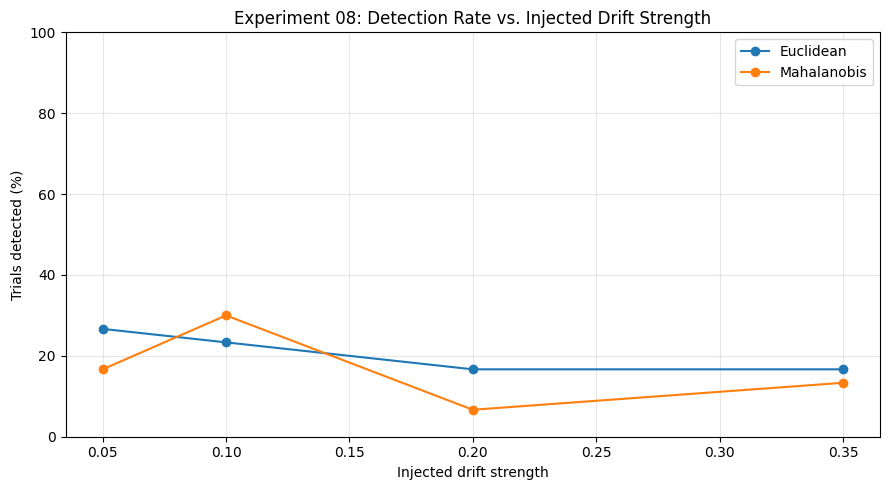

Saved: exp08_detection_rate_comparison.png


In [17]:

# Experiment 08 — Step 17: Plot revised detection rates

import matplotlib.pyplot as plt

plot_df = summary_v2_df[
    summary_v2_df["drift_strength"] > 0
].copy()

fig, ax = plt.subplots(figsize=(9, 5))

for detector, group in plot_df.groupby("detector"):
    group = group.sort_values("drift_strength")
    ax.plot(
        group["drift_strength"],
        group["detection_rate_pct"],
        marker="o",
        label=detector
    )

ax.set_title("Experiment 08: Detection Rate vs. Injected Drift Strength")
ax.set_xlabel("Injected drift strength")
ax.set_ylabel("Trials detected (%)")
ax.set_ylim(0, 100)
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()

fig.savefig("exp08_detection_rate_comparison.png", dpi=200)
plt.show()

print("Saved: exp08_detection_rate_comparison.png")


In [18]:

from google.colab import files

# Export the revised summary and trial-level data
summary_v2_df.to_csv("exp08_summary_results_v2.csv", index=False)
results_v2_df.to_csv("exp08_trial_results_v2.csv", index=False)

print("Ready to download:")
print("- exp08_detection_rate_comparison.png")
print("- exp08_summary_results_v2.csv")
print("- exp08_trial_results_v2.csv")

files.download("exp08_detection_rate_comparison.png")
files.download("exp08_summary_results_v2.csv")
files.download("exp08_trial_results_v2.csv")


Ready to download:
- exp08_detection_rate_comparison.png
- exp08_summary_results_v2.csv
- exp08_trial_results_v2.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>